In [1]:
import os
import shutil
import xml.etree.ElementTree as ET
from tqdm import tqdm
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import cv2

In [2]:
pip install ultralytics opencv-python-headless tqdm scikit-learn lxml matplotlib

  Using cached opencv_python_headless-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python_headless-5.0.0.93-cp37-abi3-win_amd64.whl (43.8 MB)
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\Jyothi KP\\anaconda3\\Lib\\site-packages\\cv2\\cv2.pyd'
Consider using the `--user` option or check the permissions.



In [3]:
import os
import shutil
import xml.etree.ElementTree as ET
from tqdm import tqdm
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import cv2

# ---------- STEP 1: Install dependencies ----------
#!pip install -q ultralytics opencv-python-headless tqdm scikit-learn lxml matplotlib

# ---------- STEP 2: Download BCCD Dataset ----------
#if not os.path.exists("BCCD_Dataset"):
#    !git clone https://github.com/Shenggan/BCCD_Dataset.git

base_dir = "C:/Users/Jyothi KP/Documents/BCCD_Dataset/BCCD/JPEGImages"
ann_dir = "C:/Users/Jyothi KP/Documents/BCCD_Dataset/BCCD/Annotations"

# ---------- STEP 3: Prepare YOLO dataset ----------
yolo_dataset = "bccd_yolo"
os.makedirs(f"{yolo_dataset}/images/train", exist_ok=True)
os.makedirs(f"{yolo_dataset}/images/val", exist_ok=True)
os.makedirs(f"{yolo_dataset}/labels/train", exist_ok=True)
os.makedirs(f"{yolo_dataset}/labels/val", exist_ok=True)

def voc_to_yolo(xml_file, img_w, img_h):
    tree = ET.parse(xml_file)
    root = tree.getroot()
    yolo_labels = []
    for obj in root.findall("object"):
        cls = obj.find("name").text
        if cls == "RBC":
            cls_id = 0
        elif cls == "WBC":
            cls_id = 1
        elif cls == "Platelets":
            cls_id = 2
        else:
            continue
        bndbox = obj.find("bndbox")
        xmin = int(bndbox.find("xmin").text)
        ymin = int(bndbox.find("ymin").text)
        xmax = int(bndbox.find("xmax").text)
        ymax = int(bndbox.find("ymax").text)
        x_center = (xmin + xmax)/2.0/img_w
        y_center = (ymin + ymax)/2.0/img_h
        w = (xmax - xmin)/img_w
        h = (ymax - ymin)/img_h
        yolo_labels.append(f"{cls_id} {x_center} {y_center} {w} {h}")
    return yolo_labels

# Split images
all_imgs = [f for f in os.listdir(base_dir) if f.endswith(".jpg")]
train_imgs, val_imgs = train_test_split(all_imgs, test_size=0.2, random_state=42)

for split, img_list in [("train", train_imgs), ("val", val_imgs)]:
    for img_name in tqdm(img_list, desc=f"Converting {split}"):
        xml_name = img_name.replace(".jpg",".xml")
        xml_path = os.path.join(ann_dir, xml_name)
        img_path = os.path.join(base_dir, img_name)
        if not os.path.exists(xml_path):
            continue
        img = cv2.imread(img_path)
        h, w = img.shape[:2]
        labels = voc_to_yolo(xml_path, w, h)
        with open(f"{yolo_dataset}/labels/{split}/{img_name.replace('.jpg','.txt')}","w") as f:
            f.write("\n".join(labels))
        shutil.copy(img_path,f"{yolo_dataset}/images/{split}/{img_name}")

print("✅ Dataset prepared in YOLO format!")

# ---------- STEP 4: Create data.yaml ----------
yaml_text = """
train: bccd_yolo/images/train
val: bccd_yolo/images/val

nc: 3
names: ['RBC','WBC','Platelets']
"""
with open("bccd.yaml","w") as f:
    f.write(yaml_text)

# ---------- STEP 5: Train YOLOv8 ----------
from ultralytics import YOLO

model = YOLO("yolov8n.pt")  # nano version
model.train(data="bccd.yaml", epochs=25, imgsz=640, batch=8, name="bccd_platelet_detector")

# ---------- STEP 6: Platelet abnormality detection (batch, no display) ----------
def analyze_platelet_shape(img, platelet_boxes, circularity_thresh=0.6):
    abnormal_indices = []
    for i, box in enumerate(platelet_boxes):
        x1, y1, x2, y2 = map(int, box)
        crop = img[y1:y2, x1:x2]
        if crop.size==0:
            continue
        gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
        gray = cv2.GaussianBlur(gray,(3,3),0)
        bw = cv2.adaptiveThreshold(gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY_INV,11,2)
        contours,_ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            continue
        cnt = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(cnt)
        if area<5:
            continue
        peri = cv2.arcLength(cnt, True)
        circularity = (4*np.pi*area)/(peri*peri+1e-5)
        if circularity < circularity_thresh:
            abnormal_indices.append(i+1)
    return abnormal_indices

# ---------- STEP 7: Compute dynamic thresholds ----------
model = YOLO("runs/detect/bccd_platelet_detector/weights/best.pt")
val_dir = "bccd_yolo/images/val"
val_imgs = [f for f in os.listdir(val_dir) if f.endswith(".jpg")]

platelet_counts = []
for img_name in val_imgs:
    img_path = os.path.join(val_dir, img_name)
    results = model(img_path, verbose=False)[0]
    cls = results.boxes.cls.cpu().numpy()
    platelet_counts.append(np.sum(cls==2))

mean_count = np.mean(platelet_counts)
std_count = np.std(platelet_counts)
low_thresh = max(1,int(mean_count - 2*std_count))
high_thresh = int(mean_count + 2*std_count)
print(f"Dynamic thresholds -> low: {low_thresh}, high: {high_thresh}")

# ---------- STEP 8: Batch process validation images ----------
report = []
for img_name in tqdm(val_imgs, desc="Processing validation images"):
    img_path = os.path.join(val_dir,img_name)
    results = model(img_path, verbose=False)[0]
    boxes = results.boxes.xyxy.cpu().numpy()
    cls = results.boxes.cls.cpu().numpy()
    platelet_boxes = boxes[cls==2]
    platelet_count = len(platelet_boxes)
    abnormal_count_flag = platelet_count < low_thresh or platelet_count > high_thresh

    img = cv2.imread(img_path)
    abnormal_shapes = analyze_platelet_shape(img, platelet_boxes)

    report.append({
        "image": img_name,
        "platelet_count": platelet_count,
        "abnormal_count": "YES" if abnormal_count_flag else "NO",
        "abnormal_shapes": abnormal_shapes,
        "num_abnormal_shapes": len(abnormal_shapes)
    })

# Save CSV
df = pd.DataFrame(report)
df.to_csv("platelet_report.csv", index=False)
print("✅ Platelet report saved as platelet_report.csv")

Converting val: 100%|█████████████████████████████████████████████████████████████████| 73/73 [00:00<00:00, 148.37it/s]


✅ Dataset prepared in YOLO format!
New https://pypi.org/project/ultralytics/8.4.202 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.227  Python-3.13.5 torch-2.9.0+cpu CPU (AMD Ryzen 5 5625U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=bccd.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=bccd_plate

Processing validation images: 100%|████████████████████████████████████████████████████| 73/73 [00:06<00:00, 11.07it/s]

✅ Platelet report saved as platelet_report.csv


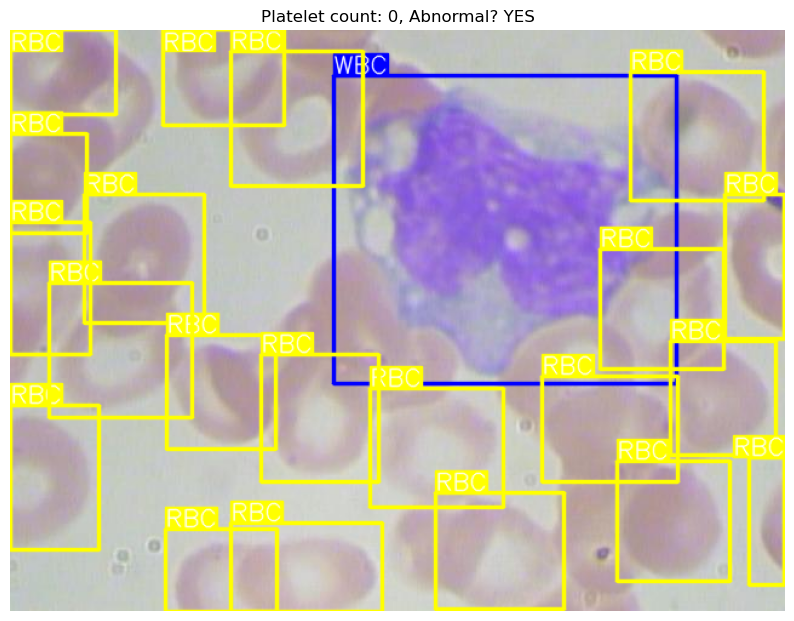

Image: C:/Users/Jyothi KP/Platelets/Platelets/bccd_yolo/images/val/BloodImage_00255.jpg
Platelet count: 0
Abnormal count? YES
Abnormal platelet shapes indices: []


In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
from ultralytics.utils.plotting import Annotator

# Load trained model
model_path = "C:/Users/Jyothi KP/Platelets/Platelets/runs/detect/bccd_platelet_detector3/weights/best.pt"
model = YOLO(model_path)

# Function to detect abnormal platelet shapes
def analyze_platelet_shape(img, platelet_boxes, circularity_thresh=0.6):
    abnormal_indices = []
    for i, box in enumerate(platelet_boxes):
        x1, y1, x2, y2 = map(int, box)
        crop = img[y1:y2, x1:x2]
        if crop.size == 0:
            continue
        gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
        gray = cv2.GaussianBlur(gray, (3,3), 0)
        bw = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY_INV, 11, 2)
        contours,_ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            continue
        cnt = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(cnt)
        if area < 5:
            continue
        peri = cv2.arcLength(cnt, True)
        circularity = (4*np.pi*area)/(peri*peri + 1e-5)
        if circularity < circularity_thresh:
            abnormal_indices.append(i+1)
    return abnormal_indices

# Function to test a single image
def test_single_image_full(image_path, low_thresh, high_thresh, circularity_thresh=0.6):
    results = model(image_path, verbose=False)[0]
    boxes = results.boxes.xyxy.cpu().numpy()
    cls = results.boxes.cls.cpu().numpy()
    names = results.names

    platelet_boxes = boxes[cls==2]
    platelet_count = len(platelet_boxes)
    abnormal_count_flag = platelet_count < low_thresh or platelet_count > high_thresh
    abnormal_shapes = analyze_platelet_shape(cv2.imread(image_path), platelet_boxes, circularity_thresh)

    # Annotate all cells
    img = cv2.imread(image_path)
    annotator = Annotator(img)
    for i, (b, c) in enumerate(zip(boxes, cls)):
        if c == 2:  # Platelets
            color = (0,0,255) if (i+1) in abnormal_shapes else (0,255,0)
        elif c == 1:  # WBC
            color = (255,0,0)
        elif c == 0:  # RBC
            color = (0,255,255)
        annotator.box_label(b, names[int(c)], color=color)
    img_annot = annotator.result()

    # Display
    %matplotlib inline
    img_rgb = cv2.cvtColor(img_annot, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10,10))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title(f"Platelet count: {platelet_count}, Abnormal? {'YES' if abnormal_count_flag else 'NO'}")
    plt.show()

    # Print summary
    print(f"Image: {image_path}")
    print(f"Platelet count: {platelet_count}")
    print(f"Abnormal count? {'YES' if abnormal_count_flag else 'NO'}")
    print(f"Abnormal platelet shapes indices: {abnormal_shapes}")

# Example usage
low_thresh = 1
high_thresh = 3

image_path = "C:/Users/Jyothi KP/Platelets/Platelets/bccd_yolo/images/val/BloodImage_00255.jpg"
test_single_image_full(image_path, low_thresh, high_thresh)

In [7]:
from ultralytics import YOLO

# Load trained model
model = YOLO(
    r"C:\Users\Jyothi KP\Platelets\Platelets\runs\detect\bccd_platelet_detector7\weights\best.pt"
)

# Display detected classes
print(model.names)

{0: 'RBC', 1: 'WBC', 2: 'Platelets'}


In [2]:
from ultralytics import YOLO

model = YOLO(
    r"C:\Users\Jyothi KP\Platelets\Platelets\runs\detect\bccd_platelet_detector7\weights\best.pt"
)

metrics = model.val(
    data=r"C:\Users\Jyothi KP\Platelets\Platelets\bccd.yaml"
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.3.227  Python-3.13.5 torch-2.9.0+cpu CPU (AMD Ryzen 5 5625U with Radeon Graphics)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.20.1 ms, read: 19.44.0 MB/s, size: 19.3 KB)
val: Scanning C:\Users\Jyothi KP\Platelets\Platelets\bccd_yolo\labels\val.cache... 73 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 73/73 89.4Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 0.7it/s 6.9s2.0ss
                   all         73       1038      0.882      0.913      0.926      0.641
                   RBC         70        864      0.782      0.839      0.876      0.618
                   WBC         72         74      0.979          1      0.993      0.808
             Platelets         49        100      0.884        0.9      0.907      0.495
Speed: 2.2ms preprocess, 69.9ms inference, 0.0ms loss, 3.7ms postprocess per image
Results saved to C:

In [3]:
from ultralytics import YOLO
import os
import pandas as pd

base_path = r"C:\Users\Jyothi KP\Platelets\Platelets\runs\detect"
data_path = r"C:\Users\Jyothi KP\Platelets\Platelets\bccd.yaml"

results_list = []

for folder in os.listdir(base_path):
    model_path = os.path.join(base_path, folder, "weights", "best.pt")

    if os.path.exists(model_path):
        print(f"\nEvaluating: {folder}")

        model = YOLO(model_path)
        metrics = model.val(data=data_path)

        results_list.append({
            "Model": folder,
            "Precision": metrics.box.mp,
            "Recall": metrics.box.mr,
            "mAP50": metrics.box.map50,
            "mAP50-95": metrics.box.map
        })

comparison = pd.DataFrame(results_list)
display(comparison.sort_values(by="mAP50", ascending=False))


Evaluating: bccd_platelet_detector
Ultralytics 8.3.227  Python-3.13.5 torch-2.9.0+cpu CPU (AMD Ryzen 5 5625U with Radeon Graphics)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 77.318.4 MB/s, size: 20.9 KB)
val: Scanning C:\Users\Jyothi KP\Platelets\Platelets\bccd_yolo\labels\val.cache... 73 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 73/73 78.5Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 0.8it/s 6.3s1.8ss
                   all         73       1038      0.834      0.909      0.908      0.604
                   RBC         70        864      0.738      0.868      0.848      0.585
                   WBC         72         74      0.904          1      0.989      0.779
             Platelets         49        100       0.86       0.86      0.887      0.446
Speed: 1.8ms preprocess, 72.0ms inference, 0.0ms loss, 4.4ms post

,Model,Precision,Recall,mAP50,mAP50-95
1,bccd_platelet_detector2,0.881575,0.912954,0.925724,0.640508
2,bccd_platelet_detector3,0.881575,0.912954,0.925724,0.640508
6,bccd_platelet_detector7,0.881575,0.912954,0.925724,0.640508
5,bccd_platelet_detector6,0.853454,0.901499,0.913392,0.625296
0,bccd_platelet_detector,0.834140,0.909352,0.908046,0.603554
4,bccd_platelet_detector5,0.780477,0.900584,0.900669,0.588491
3,bccd_platelet_detector4,0.875714,0.344910,0.448266,0.292408


In [4]:
import hashlib
import os

base = r"C:\Users\Jyothi KP\Platelets\Platelets\runs\detect"

for name in ["bccd_platelet_detector2",
             "bccd_platelet_detector3",
             "bccd_platelet_detector7"]:

    path = os.path.join(base, name, "weights", "best.pt")

    with open(path, "rb") as f:
        file_hash = hashlib.md5(f.read()).hexdigest()

    print(name, file_hash)

bccd_platelet_detector2 ad76ec89a31eed4b11686d491dbb108c
bccd_platelet_detector3 2bb96ed2fcd32fb56b153f12981cb45c
bccd_platelet_detector7 27bd72186e4cc4b62f1e80620121cf9c


In [ ]:
from ultralytics import YOLO

# Load pretrained YOLOv8 Nano
model = YOLO("yolov8n.pt")

# New training experiment
model.train(
    data=r"C:\Users\Jyothi KP\Platelets\Platelets\bccd.yaml",
    epochs=25,
    imgsz=800,
    batch=4,
    name="bccd_platelet_detector8_img800",
    device="cpu"
)

WARNING Download failure, retrying 1/3 https://github.com/ultralytics/assets/releases/download/v8.3.0/yolov8n.pt... <urlopen error [WinError 10060] A connection attempt failed because the connected party did not properly respond after a period of time, or established connection failed because connected host has failed to respond>
WARNING Download failure, retrying 2/3 https://github.com/ultralytics/assets/releases/download/v8.3.0/yolov8n.pt... Curl return value 35
WARNING Download failure, retrying 3/3 https://github.com/ultralytics/assets/releases/download/v8.3.0/yolov8n.pt... Curl return value 35
New https://pypi.org/project/ultralytics/8.4.202 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.227  Python-3.13.5 torch-2.9.0+cpu CPU (AMD Ryzen 5 5625U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=

In [ ]:
from ultralytics import YOLO

model = YOLO(
    r"runs\detect\bccd_platelet_detector8_img800\weights\best.pt"
)

metrics = model.val(
    data=r"C:\Users\Jyothi KP\Platelets\Platelets\bccd.yaml"
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)